# 都道府県別人口から考える地域サービスの展開

- **氏名：** 芳賀慶次
- **依頼元：** 全国で生活支援サービスを展開する団体
- **読み手：** 事業企画担当者
- **調べたい問い：** 2020年の都道府県別人口にはどのような違いがあるか。人口データから、生活支援サービスの展開について何が提案できるか。

## 分析の目的
人口が多い地域と少ない地域を比べ、人口の偏りを確認する。人口の多さだけでサービスの必要性が決まるわけではないが、サービスを届ける対象となる人数や、地域ごとの展開方法を考えるための基礎資料として使う。

**前回からの改善点：** 前回は人口上位10都道府県のランキングが中心だった。今回は上位10都道府県が全国人口に占める割合、人口が少ない地域との比較、人口分布のグラフも追加する。

## 1. データの読み込み

前回使用した2020年の都道府県別人口CSVを読み込む。今回は授業のグラフ資料に合わせて、Python標準ライブラリの`csv`を使う。pandasは使用しない。

In [1]:
import csv
import matplotlib.pyplot as plt

with open("prefecture_population_2020.csv", encoding="utf-8-sig", newline="") as file:
    data = list(csv.DictReader(file))

print("都道府県の数：", len(data))
print("最初のデータ：", data[0])

都道府県の数： 47
最初のデータ： {'都道府県': '北海道', '人口': '5224614'}


## 2. データの確認

47都道府県分のデータがあることと、人口が数値として扱えることを確認する。

In [2]:
populations = [int(row["人口"]) for row in data]
print("データ件数：", len(populations))
print("人口の合計：", format(sum(populations), ",d"), "人")
print("最大人口：", format(max(populations), ",d"), "人")
print("最小人口：", format(min(populations), ",d"), "人")

データ件数： 47
人口の合計： 126,146,099 人
最大人口： 14,047,594 人
最小人口： 553,407 人


## 3. 人口上位10都道府県のランキング

人口が多い順に並べ、上位10都道府県を表示する。ランキングにすることで、人口が集中している地域を確認する。

In [3]:
top10 = sorted(data, key=lambda row: int(row["人口"]), reverse=True)[:10]

print("人口上位10都道府県")
for rank, row in enumerate(top10, start=1):
    print(f"{rank:2}位 {row['都道府県']}：{int(row['人口']):,}人")

人口上位10都道府県
 1位 東京都：14,047,594人
 2位 神奈川県：9,237,337人
 3位 大阪府：8,837,685人
 4位 愛知県：7,542,415人
 5位 埼玉県：7,344,765人
 6位 千葉県：6,284,480人
 7位 兵庫県：5,465,002人
 8位 北海道：5,224,614人
 9位 福岡県：5,135,214人
10位 静岡県：3,633,202人


## 4. 上位10都道府県が全国人口に占める割合

上位10都道府県の人口を合計し、47都道府県の人口合計に対する割合を計算する。人数だけでなく割合で見ることで、人口がどの程度集中しているかを把握する。

In [4]:
total_population = sum(int(row["人口"]) for row in data)
top10_population = sum(int(row["人口"]) for row in top10)
top10_share = top10_population / total_population * 100

print("全国人口：", format(total_population, ",d"), "人")
print("上位10都道府県の人口：", format(top10_population, ",d"), "人")
print(f"全国人口に占める割合：{top10_share:.1f}%")

全国人口： 126,146,099 人
上位10都道府県の人口： 72,752,308 人
全国人口に占める割合：57.7%


## 5. 人口上位10都道府県の棒グラフ

上位10都道府県の人口を棒グラフで比較する。横軸は都道府県、縦軸は人口（百万人）である。

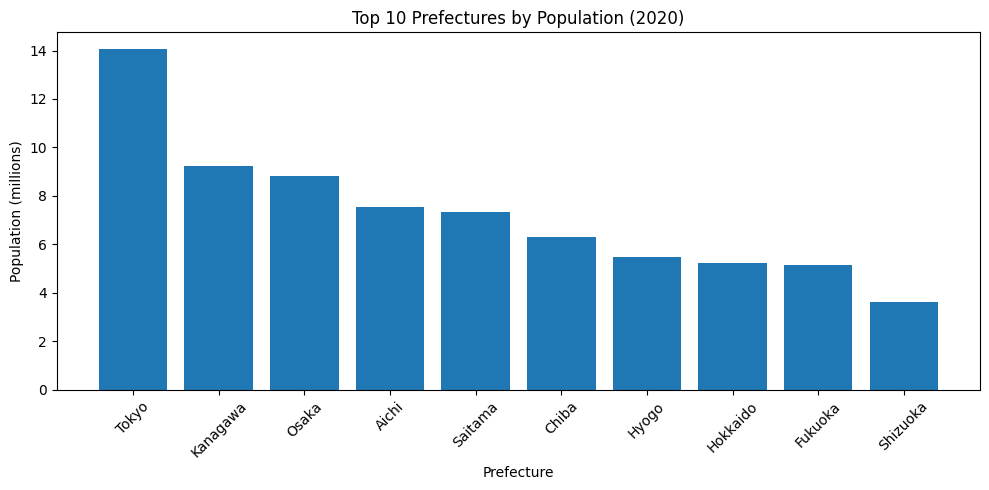

In [5]:
english_names = ["Tokyo", "Kanagawa", "Osaka", "Aichi", "Saitama", "Chiba", "Hyogo", "Hokkaido", "Fukuoka", "Shizuoka"]
values = [int(row["人口"]) / 1_000_000 for row in top10]

plt.figure(figsize=(10, 5))
plt.bar(english_names, values)
plt.title("Top 10 Prefectures by Population (2020)")
plt.xlabel("Prefecture")
plt.ylabel("Population (millions)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 6. 人口分布のヒストグラム

47都道府県の人口をいくつかの範囲に分け、どのくらいの人口規模の県が多いかを確認する。横軸は人口（百万人）、縦軸は都道府県数である。

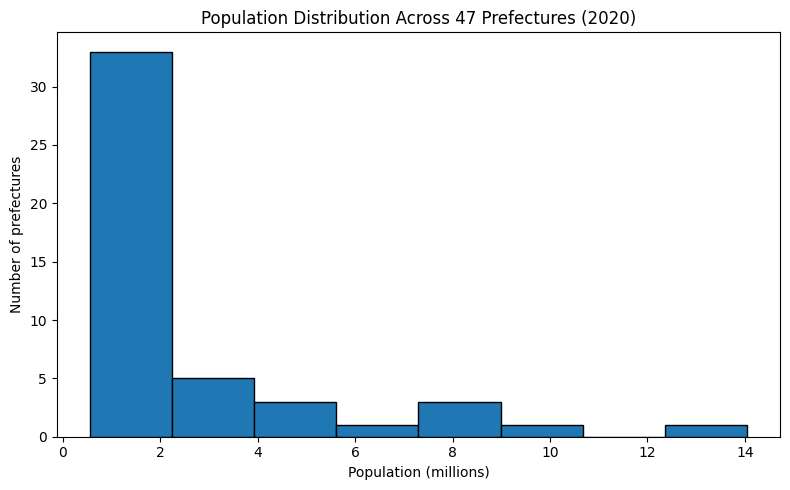

In [6]:
population_millions = [value / 1_000_000 for value in populations]

plt.figure(figsize=(8, 5))
plt.hist(population_millions, bins=8, edgecolor="black")
plt.title("Population Distribution Across 47 Prefectures (2020)")
plt.xlabel("Population (millions)")
plt.ylabel("Number of prefectures")
plt.tight_layout()
plt.show()

## 7. 人口が多い地域と少ない地域の比較

人口が最も多い都道府県と最も少ない都道府県を取り出し、差を計算する。

In [7]:
largest = max(data, key=lambda row: int(row["人口"]))
smallest = min(data, key=lambda row: int(row["人口"]))
difference = int(largest["人口"]) - int(smallest["人口"])
ratio = int(largest["人口"]) / int(smallest["人口"])

print(f"最も人口が多い都道府県：{largest['都道府県']}（{int(largest['人口']):,}人）")
print(f"最も人口が少ない都道府県：{smallest['都道府県']}（{int(smallest['人口']):,}人）")
print(f"人口の差：{difference:,}人")
print(f"人口の比：約{ratio:.1f}倍")

最も人口が多い都道府県：東京都（14,047,594人）
最も人口が少ない都道府県：鳥取県（553,407人）
人口の差：13,494,187人
人口の比：約25.4倍


## 8. わかったこと・考察

今回の分析では、2020年の人口は東京都が最も多く、鳥取県が最も少なかった。人口上位の都道府県には東京・神奈川・大阪・愛知などの大都市圏が多く、人口が一部の地域に集まっていることが分かった。また、上位10都道府県の人口が全国に占める割合を見ることで、人口の集中を人数だけでなく割合からも確認できた。

ヒストグラムからは、人口が数百万人規模の都道府県が多い一方、東京都のように特に人口が多い地域もあり、都道府県ごとの差が大きいことが分かる。人口が多い地域では多くの人にサービスを届けられる反面、利用者も多くなるため、拠点や人員を十分に用意する必要がある。人口が少ない地域では、利用者が広い範囲に分散している可能性があるため、巡回型のサービスやオンライン相談などが役立つと考える。

## 9. 組織への提案

生活支援サービスを展開する際は、人口が多い地域だけに注目するのではなく、地域の人口規模に合わせて提供方法を変えることを提案する。人口が多い都市部では利用しやすい場所に拠点を設け、人口が少ない地域では巡回やオンラインを組み合わせるとよいと考える。

ただし、今回使ったデータは2020年の都道府県別の総人口であり、年齢構成、交通手段、地域内の人口の分布、サービスへの需要までは分からない。そのため、実際にサービスを始める前には、より新しい人口データや市区町村別のデータ、高齢者人口、交通事情なども確認する必要がある。

## 10. データの出典と注意点

- **データ：** 2020年 都道府県別人口（47都道府県）
- **ファイル：** `prefecture_population_2020.csv`
- **出典：** 前回の課題で使用した配布・保存データ
- **注意点：** 2020年時点の人口データであり、現在の人口を示すものではない。また、人口だけで地域のサービス需要を判断することはできない。